# LSTM(Long Short-Term Memory) 구조

<img src = "./image/DL_이미지모음/rnn_lstm.jpg">

- 단기 기억을 오래 기억하기 위해 고안되었음

<img src = "./image/DL_이미지모음/lstm.png" height = "700" width = "700">

- 은닉 상태를 만드는 방법
    - output gate layer(출력 게이트)
        1. 입력과 이전 타임스텝의 은닉 상태를 가중치에 곱한 후 활성화 함수를 통과시켜 다음 은닉 상태를 만듦
            - 이 때 기본 순환층과는 달리 시그모이드 활성화 함수를 사용
        2. tanh 활성화 함수를 통과한 값과 곱해져서 은닉 상태를 만듦
     
- LSTM 은 순환 되는 상태가 2개
    - 은닉 상태
    - 셀 상태(cell state)
        - 다음 층으로 전달되지 않고 LSTM 셀에서 순환만 되는 값
     
- 셀 상태를 계산하는 과정
    - forget gate layer(삭제 게이트)
        - 정보를 제거하는 역할
        1. 입력과 은닉 상태를 또 다른 가중치에 곱한 다음 시그모이드 함수를 통과
        2. 이전 타임스텝의 셀 상태와 곱하여 새로운 셀 상태를 만듦
            - 이 셀 상태가 오른쪽에서 tanh 함수를 통과하여 새로운 은닉 상태를 만드는 데 기여
          
    - input gate layer(입력 게이트)
        - 새로운 정보를 셀 상태에 추가
        1. 입력과 은닉 상태를 각기 다른 가중치에 곱함
        2. 하나는 시그모이드 함수, 하나는 tanh 함수를 통과
        3. 두 결과를 곱함
        4. 이전 셀 상태와 더함

## 데이터 준비

In [1]:
from tensorflow.keras.datasets import imdb
from tensorflow.keras.preprocessing.sequence import pad_sequences
from tensorflow import keras
from sklearn.model_selection import train_test_split
import matplotlib.pyplot as plt

In [2]:
# 데이터 로드
(x_train, y_train), (x_test, y_test) = imdb.load_data(num_words = 500)

In [3]:
# 훈련 세트와 검증 세트로 나누기
x_train, x_val, y_train, y_val = train_test_split(x_train, y_train, test_size = 0.2,
                                                  stratify = y_train, random_state = 26)

In [4]:
# 패딩
train_seq = pad_sequences(x_train, maxlen = 100)
val_seq = pad_sequences(x_val, maxlen = 100)

In [5]:
# LSTM 모델 생성
model = keras.Sequential()
model.add(keras.Input(shape = (100,)))
model.add(keras.layers.Embedding(500, 128))
model.add(keras.layers.LSTM(8))
model.add(keras.layers.Dense(1, activation = "sigmoid"))

In [6]:
model.summary()

Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━┓
┃ Layer (type)                         ┃ Output Shape                ┃         Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━┩
│ embedding (Embedding)                │ (None, 100, 128)            │          64,000 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ lstm (LSTM)                          │ (None, 8)                   │           4,384 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dense (Dense)                        │ (None, 1)                   │               9 │
└──────────────────────────────────────┴─────────────────────────────┴─────────────────┘

 Total params: 68,393 (267.16 KB)

 Trainable params: 68,393 (267.16 KB)

 Non-trainable params: 0 (0.00 B)

- LSTM 셀 파라미터 개수
    - ((128 * 8) + (8 * 8) + 8) * 4 = 4384

In [8]:
rmsprop = keras.optimizers.RMSprop(learning_rate = 1e-4)
model.compile(optimizer = rmsprop, loss = "binary_crossentropy", metrics = ["accuracy"])
cp_cb = keras.callbacks.ModelCheckpoint("./model/best-lstm-model.keras", save_best_only = True)
es_cb = keras.callbacks.EarlyStopping(patience = 4, restore_best_weights = True)

In [9]:
history = model.fit(train_seq, y_train, epochs = 100, batch_size = 64,
                    validation_data = (val_seq, y_val), callbacks = [cp_cb, es_cb])

Epoch 1/100
313/313 ━━━━━━━━━━━━━━━━━━━━ 12s 29ms/step - accuracy: 0.5506 - loss: 0.6911 - val_accuracy: 0.6048 - val_loss: 0.6845
Epoch 2/100
313/313 ━━━━━━━━━━━━━━━━━━━━ 7s 23ms/step - accuracy: 0.6300 - loss: 0.6792 - val_accuracy: 0.6688 - val_loss: 0.6565
Epoch 3/100
313/313 ━━━━━━━━━━━━━━━━━━━━ 8s 26ms/step - accuracy: 0.6943 - loss: 0.6324 - val_accuracy: 0.7282 - val_loss: 0.5701
Epoch 4/100
313/313 ━━━━━━━━━━━━━━━━━━━━ 8s 27ms/step - accuracy: 0.7406 - loss: 0.5594 - val_accuracy: 0.7516 - val_loss: 0.5417
Epoch 5/100
313/313 ━━━━━━━━━━━━━━━━━━━━ 8s 25ms/step - accuracy: 0.7664 - loss: 0.5259 - val_accuracy: 0.7702 - val_loss: 0.5195
Epoch 6/100
313/313 ━━━━━━━━━━━━━━━━━━━━ 8s 24ms/step - accuracy: 0.7807 - loss: 0.5051 - val_accuracy: 0.7606 - val_loss: 0.5160
Epoch 7/100
313/313 ━━━━━━━━━━━━━━━━━━━━ 8s 26ms/step - accuracy: 0.7889 - loss: 0.4887 - val_accuracy: 0.7770 - val_loss: 0.4912
Epoch 8/100
313/313 ━━━━━━━━━━━━━━━━━━━━ 9s 28ms/step - accuracy: 0.7987 - loss: 0.4686 -

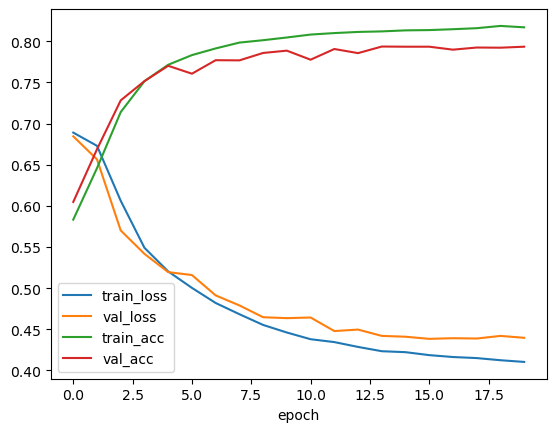

In [10]:
plt.figure()

plt.plot(history.history["loss"], label = "train_loss")
plt.plot(history.history["val_loss"], label = "val_loss")
plt.plot(history.history["accuracy"], label = "train_acc")
plt.plot(history.history["val_accuracy"], label = "val_acc")

plt.xlabel("epoch")
plt.legend()
plt.show()

# 순환층에 드롭아웃 적용

- 순환층은 자체적으로 드롭아웃 기능을 제공
    - SimpleRNN 과 LSTM 클래스 모두 dropout 매개변수와 recurrent_dropout 매개변수를 가지고 있음
        - dropout : 셀의 입력에 드롭아웃을 적용
        - recurrent_dropout : 순환되는 은닉 상태에 드롭아웃을 적용
            - 버전에 따라 recurrent_dropout 이 GPU 를 사용하지 못하는 경우가 있음

In [11]:
model2 = keras.Sequential()
model2.add(keras.Input(shape = (100,)))
model2.add(keras.layers.Embedding(500, 128))
model2.add(keras.layers.LSTM(8, dropout = 0.3))
model2.add(keras.layers.Dense(1, activation = "sigmoid"))

In [12]:
rmsprop = keras.optimizers.RMSprop(learning_rate = 1e-4)
model2.compile(optimizer = rmsprop, loss = "binary_crossentropy", metrics = ["accuracy"])
cp_cb = keras.callbacks.ModelCheckpoint("./model/best-dropout-model.keras", save_best_only = True)
es_cb = keras.callbacks.EarlyStopping(patience = 4, restore_best_weights = True)

In [13]:
history = model2.fit(train_seq, y_train, epochs = 100, batch_size = 64,
                     validation_data = (val_seq, y_val), callbacks = [cp_cb, es_cb])

Epoch 1/100
313/313 ━━━━━━━━━━━━━━━━━━━━ 11s 27ms/step - accuracy: 0.5208 - loss: 0.6921 - val_accuracy: 0.5662 - val_loss: 0.6899
Epoch 2/100
313/313 ━━━━━━━━━━━━━━━━━━━━ 8s 27ms/step - accuracy: 0.5806 - loss: 0.6881 - val_accuracy: 0.5944 - val_loss: 0.6836
Epoch 3/100
313/313 ━━━━━━━━━━━━━━━━━━━━ 8s 24ms/step - accuracy: 0.6154 - loss: 0.6797 - val_accuracy: 0.6338 - val_loss: 0.6680
Epoch 4/100
313/313 ━━━━━━━━━━━━━━━━━━━━ 9s 27ms/step - accuracy: 0.6525 - loss: 0.6573 - val_accuracy: 0.6924 - val_loss: 0.6198
Epoch 5/100
313/313 ━━━━━━━━━━━━━━━━━━━━ 8s 24ms/step - accuracy: 0.7060 - loss: 0.5957 - val_accuracy: 0.7380 - val_loss: 0.5514
Epoch 6/100
313/313 ━━━━━━━━━━━━━━━━━━━━ 8s 24ms/step - accuracy: 0.7449 - loss: 0.5430 - val_accuracy: 0.7460 - val_loss: 0.5313
Epoch 7/100
313/313 ━━━━━━━━━━━━━━━━━━━━ 8s 25ms/step - accuracy: 0.7666 - loss: 0.5125 - val_accuracy: 0.7532 - val_loss: 0.5168
Epoch 8/100
313/313 ━━━━━━━━━━━━━━━━━━━━ 8s 26ms/step - accuracy: 0.7715 - loss: 0.4957 -

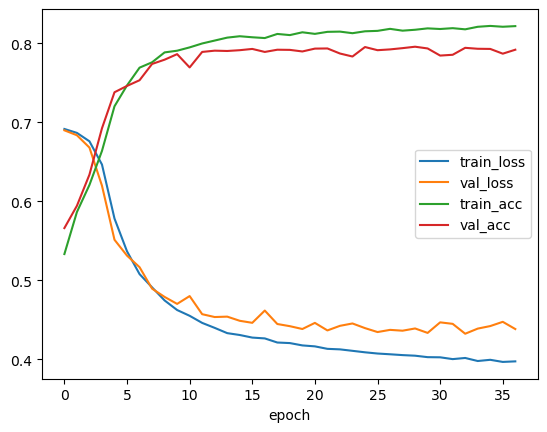

In [14]:
plt.figure()

plt.plot(history.history["loss"], label = "train_loss")
plt.plot(history.history["val_loss"], label = "val_loss")
plt.plot(history.history["accuracy"], label = "train_acc")
plt.plot(history.history["val_accuracy"], label = "val_acc")

plt.xlabel("epoch")
plt.legend()
plt.show()

# 2개의 층을 연결

- 순환층을 연결할 때의 주의점
    - 순환층의 은닉 상태는 샘플의 마지막 타임스텝에 대한 은닉 상태만 다음 층으로 전달
        - 순환층을 쌓게 되면 모든 순환층에 순차 데이터가 필요함
        - 앞쪽의 순환층이 모든 타임스텝에 대한 은닉 상태를 출력해야함
            - return_sequences = True 로 지정

In [17]:
model3 = keras.Sequential()
model3.add(keras.Input(shape = (100,)))
model3.add(keras.layers.Embedding(500, 128))
model3.add(keras.layers.LSTM(8, dropout = 0.3, return_sequences = True))
model3.add(keras.layers.LSTM(8, dropout = 0.3))
model3.add(keras.layers.Dense(1, activation = "sigmoid"))

In [18]:
model3.summary()

Model: "sequential_4"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━┓
┃ Layer (type)                         ┃ Output Shape                ┃         Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━┩
│ embedding_2 (Embedding)              │ (None, 100, 128)            │          64,000 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ lstm_3 (LSTM)                        │ (None, 100, 8)              │           4,384 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ lstm_4 (LSTM)                        │ (None, 8)                   │             544 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dense_2 (Dense)                      │ (None, 1)                   │               9 │
└──────────────────────────────────────┴─────────────────────────────┴─────────────────┘

 Total params: 68,937 (269.29 KB)

 Trainable params: 68,937 (269.29 KB)

 Non-trainable params: 0 (0.00 B)

- 첫 번째 LSTM
    - 모든 타임스텝(100개)의 은닉 상태를 출력하기 때문에 출력의 크기가 (None, 100, 8)
    - 파라미터의 수 : ((128 * 8) + (8 * 8) + 8) * 4 = 4384
 
- 두 번째 LSTM
    - 마지막 타임스텝의 은닉 상태만 출력하기 때문에 출력의 크기가 (None, 8)
    - 파라미터의 수 : ((8 * 8) + (8 * 8) + 8) * 4 = 544

In [21]:
rmsprop = keras.optimizers.RMSprop(learning_rate = 1e-4)
model3.compile(optimizer = rmsprop, loss = "binary_crossentropy", metrics = ["accuracy"])
cp_cb = keras.callbacks.ModelCheckpoint("./model/best-2rnn-model.keras", save_best_only = True)
es_cb = keras.callbacks.EarlyStopping(patience = 4, restore_best_weights = True)

In [22]:
history = model3.fit(train_seq, y_train, epochs = 100, batch_size = 64,
                     validation_data = (val_seq, y_val), callbacks = [cp_cb, es_cb])

Epoch 1/100
313/313 ━━━━━━━━━━━━━━━━━━━━ 19s 46ms/step - accuracy: 0.5203 - loss: 0.6927 - val_accuracy: 0.6036 - val_loss: 0.6906
Epoch 2/100
313/313 ━━━━━━━━━━━━━━━━━━━━ 14s 43ms/step - accuracy: 0.5940 - loss: 0.6889 - val_accuracy: 0.6286 - val_loss: 0.6816
Epoch 3/100
313/313 ━━━━━━━━━━━━━━━━━━━━ 12s 39ms/step - accuracy: 0.6325 - loss: 0.6750 - val_accuracy: 0.6660 - val_loss: 0.6471
Epoch 4/100
313/313 ━━━━━━━━━━━━━━━━━━━━ 13s 41ms/step - accuracy: 0.6652 - loss: 0.6372 - val_accuracy: 0.7068 - val_loss: 0.5841
Epoch 5/100
313/313 ━━━━━━━━━━━━━━━━━━━━ 15s 46ms/step - accuracy: 0.7099 - loss: 0.5804 - val_accuracy: 0.7152 - val_loss: 0.5578
Epoch 6/100
313/313 ━━━━━━━━━━━━━━━━━━━━ 12s 39ms/step - accuracy: 0.7360 - loss: 0.5482 - val_accuracy: 0.7444 - val_loss: 0.5242
Epoch 7/100
313/313 ━━━━━━━━━━━━━━━━━━━━ 12s 38ms/step - accuracy: 0.7541 - loss: 0.5202 - val_accuracy: 0.7600 - val_loss: 0.5084
Epoch 8/100
313/313 ━━━━━━━━━━━━━━━━━━━━ 12s 38ms/step - accuracy: 0.7646 - loss: 0

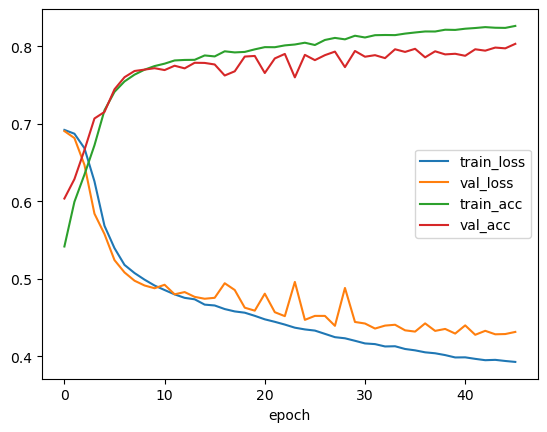

In [23]:
plt.figure()

plt.plot(history.history["loss"], label = "train_loss")
plt.plot(history.history["val_loss"], label = "val_loss")
plt.plot(history.history["accuracy"], label = "train_acc")
plt.plot(history.history["val_accuracy"], label = "val_acc")

plt.xlabel("epoch")
plt.legend()
plt.show()

# GRU(Grated Recurrent Unit) 구조

<img src = "./image/DL_이미지모음/rnn_lstm_gru.png">

- LSTM 을 간소화한 버전

- LSTM처럼 셀 상태를 계산하지 않고 은닉 상태 하나만 포함

- LSTM보다 가중치가 적기 때문에 계산량이 적지만 성능은 LSTM 과 유사함
    - 데이터 양이 적을 때는 GRU의 성능이 더 좋고 데이터 양이 많을 때는 LSTM 의 성능이 더 좋아지는 경향이 있음
    - GRU와 LSTM 중 어떤 것이 더 낫다라고 말할 수는 없음

<img src = "./image/DL_이미지모음/gru.png" height = "600" width = "600">

- GRU 셀에는 은닉 상태와 입력에 가중치를 곱하고 절편을 더하는 작은 셀 3개가 들어 있음
    - 2개는 시그모이드 활성화 함수를 사용하고 하나는 tanh 활성화 함수를 사용
 
- reset_gate
    - 셀의 출력이 은닉 상태에 바로 곱해져 삭제 게이트 역할을 수행
 
- update_gate
    - 어떤 정보를 얼마만큼 유지하고 어떤 정보를 추가할지 결정하는 역할

In [24]:
model4 = keras.Sequential()
model4.add(keras.Input(shape = (100,)))
model4.add(keras.layers.Embedding(500, 128))
model4.add(keras.layers.GRU(8, dropout = 0.3))
model4.add(keras.layers.Dense(1, activation = "sigmoid"))

In [25]:
model4.summary()

Model: "sequential_5"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━┓
┃ Layer (type)                         ┃ Output Shape                ┃         Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━┩
│ embedding_3 (Embedding)              │ (None, 100, 128)            │          64,000 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ gru (GRU)                            │ (None, 8)                   │           3,312 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dense_3 (Dense)                      │ (None, 1)                   │               9 │
└──────────────────────────────────────┴─────────────────────────────┴─────────────────┘

 Total params: 67,321 (262.97 KB)

 Trainable params: 67,321 (262.97 KB)

 Non-trainable params: 0 (0.00 B)

In [27]:
((128 * 8) + (8 * 8) + 8 + 8) * 3

3312

In [28]:
rmsprop = keras.optimizers.RMSprop(learning_rate = 1e-4)
model4.compile(optimizer = rmsprop, loss = "binary_crossentropy", metrics = ["accuracy"])
cp_cb = keras.callbacks.ModelCheckpoint("./model/best-gru-model.keras", save_best_only = True)
es_cb = keras.callbacks.EarlyStopping(patience = 4, restore_best_weights = True)

In [29]:
history = model4.fit(train_seq, y_train, epochs = 100, batch_size = 64,
                     validation_data = (val_seq, y_val), callbacks = [cp_cb, es_cb])

Epoch 1/100
313/313 ━━━━━━━━━━━━━━━━━━━━ 13s 33ms/step - accuracy: 0.5277 - loss: 0.6915 - val_accuracy: 0.5668 - val_loss: 0.6866
Epoch 2/100
313/313 ━━━━━━━━━━━━━━━━━━━━ 10s 31ms/step - accuracy: 0.5787 - loss: 0.6837 - val_accuracy: 0.5886 - val_loss: 0.6785
Epoch 3/100
313/313 ━━━━━━━━━━━━━━━━━━━━ 11s 36ms/step - accuracy: 0.5956 - loss: 0.6739 - val_accuracy: 0.6004 - val_loss: 0.6677
Epoch 4/100
313/313 ━━━━━━━━━━━━━━━━━━━━ 11s 35ms/step - accuracy: 0.6219 - loss: 0.6589 - val_accuracy: 0.6150 - val_loss: 0.6540
Epoch 5/100
313/313 ━━━━━━━━━━━━━━━━━━━━ 10s 31ms/step - accuracy: 0.6348 - loss: 0.6436 - val_accuracy: 0.6336 - val_loss: 0.6377
Epoch 6/100
313/313 ━━━━━━━━━━━━━━━━━━━━ 12s 37ms/step - accuracy: 0.6598 - loss: 0.6242 - val_accuracy: 0.6544 - val_loss: 0.6185
Epoch 7/100
313/313 ━━━━━━━━━━━━━━━━━━━━ 12s 37ms/step - accuracy: 0.6784 - loss: 0.6003 - val_accuracy: 0.6806 - val_loss: 0.5956
Epoch 8/100
313/313 ━━━━━━━━━━━━━━━━━━━━ 11s 36ms/step - accuracy: 0.7005 - loss: 0

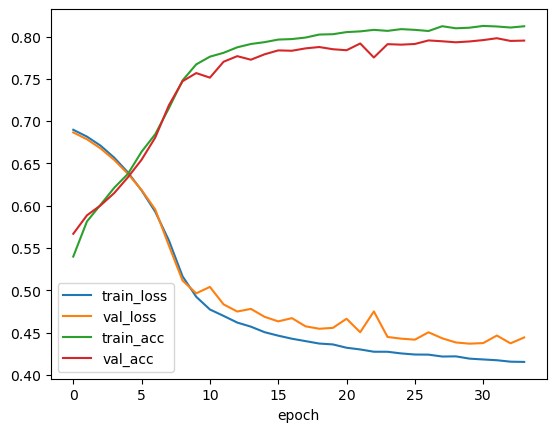

In [30]:
plt.figure()

plt.plot(history.history["loss"], label = "train_loss")
plt.plot(history.history["val_loss"], label = "val_loss")
plt.plot(history.history["accuracy"], label = "train_acc")
plt.plot(history.history["val_accuracy"], label = "val_acc")

plt.xlabel("epoch")
plt.legend()
plt.show()

# best model 검증

In [31]:
test_seq = pad_sequences(x_test, maxlen = 100)

In [32]:
rnn_model = keras.models.load_model("./model/best-2rnn-model.keras")

In [33]:
rnn_model.evaluate(test_seq, y_test)

782/782 ━━━━━━━━━━━━━━━━━━━━ 8s 10ms/step - accuracy: 0.8075 - loss: 0.4206


[0.4207479953765869, 0.8068000078201294]